# NDR — Notebook 1: Diagnosis & Local Validation Engine

## 1. Setup

In [1]:
!pip install -q 'setuptools<81'
!pip install -q 'git+https://github.com/facebookresearch/detectron2.git'

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 5.8 MB/s eta 0:00:00


In [2]:
import copy, json, pickle, random, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
import cv2, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.engine import DefaultPredictor

ROOT = '/kaggle/input/competitions/neural-debris-removal-in-streak-detection-models'
POISONED_WEIGHTS = f'{ROOT}/poisoned_model/poisoned_model.pth'
UNLEARN_DIR = f'{ROOT}/unlearn_set'
TEST_DIR    = f'{ROOT}/test_set/test_set'

BASE_CONFIG          = 'COCO-Detection/retinanet_R_50_FPN_3x.yaml'
ANCHOR_ASPECT_RATIOS = [0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0]
ANCHOR_SIZES         = [[16], [32], [64], [128], [256]]
NUM_CLASSES = 1
IMG_W = IMG_H = 1024

A_FACTOR = 10.0
IOU_THRESHOLDS = np.round(np.arange(0.2, 0.91, 0.1), 2)
CAND_THRESH = 0.05     # recall cao khi lấy candidate
CLEAN_CONF_FLOOR = 0.2 # clean model chỉ xuất conf > 0.2
MATCH_IOU = 0.3
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
WORK = Path('/kaggle/working'); WORK.mkdir(exist_ok=True)
print('Setup OK | device:', DEVICE)

Setup OK | device: cuda


## 2. Image loader + poisoned predictor

In [3]:
def load_image(path):
    im = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if im.dtype == np.uint16:
        im = im.astype(np.float32) / 65535.0
    im = np.clip(im * 255, 0, 255).astype(np.float32)
    if im.ndim == 2:
        im = np.repeat(im[:, :, None], 3, axis=2)
    return im

def build_predictor(weights, score_thresh):
    cfg = get_cfg()
    cfg.merge_from_file(model_zoo.get_config_file(BASE_CONFIG))
    cfg.MODEL.WEIGHTS = weights
    cfg.MODEL.RETINANET.NUM_CLASSES = NUM_CLASSES
    cfg.MODEL.ANCHOR_GENERATOR.ASPECT_RATIOS = [ANCHOR_ASPECT_RATIOS]
    cfg.MODEL.ANCHOR_GENERATOR.SIZES = ANCHOR_SIZES
    cfg.MODEL.RETINANET.SCORE_THRESH_TEST = score_thresh
    cfg.MODEL.DEVICE = DEVICE
    cfg.INPUT.FORMAT = 'RGB'
    return DefaultPredictor(cfg)

def predict_image(predictor, img):
    inst = predictor(img)['instances'].to('cpu')
    return inst.pred_boxes.tensor.numpy().astype(np.float32), inst.scores.numpy().astype(np.float32)

# poison boxes (COCO xywh -> xyxy), per image stem
with open(Path(UNLEARN_DIR) / 'annotations_coco.json') as f:
    coco = json.load(f)
stem_by_id = {im['id']: Path(im['file_name']).stem for im in coco['images']}
poison_boxes_by_stem = {}
for a in coco['annotations']:
    x, y, w, h = a['bbox']
    poison_boxes_by_stem.setdefault(stem_by_id[a['image_id']], []).append([x, y, x+w, y+h])
poison_boxes_by_stem = {k: np.array(v, np.float32) for k, v in poison_boxes_by_stem.items()}
unlearn_files = sorted(Path(UNLEARN_DIR).glob('*.png'), key=lambda p: int(p.stem))
unlearn_imgs = {p.stem: load_image(p) for p in unlearn_files}
print('unlearn images:', len(unlearn_files), '| poison boxes:', sum(len(v) for v in poison_boxes_by_stem.values()))

poisoned_predictor = build_predictor(POISONED_WEIGHTS, CAND_THRESH)
print('poisoned predictor ready')

Loading config /usr/local/lib/python3.12/dist-packages/detectron2/model_zoo/configs/COCO-Detection/../Base-RetinaNet.yaml with yaml.unsafe_load. Your machine may be at risk if the file contains malicious content.


unlearn images: 20 | poison boxes: 20
poisoned predictor ready


## 3. Metric core — EXACT maCADD (unit-tested)

Cài đúng theo trang đánh giá: Hungarian match theo IoU, phạt bất đối xứng A=10,
sweep IoU {0.2..0.9} với trọng số = giá trị IoU. Clean reference cắt ở conf>0.2.
`is_poison[i]` = nhãn của object clean thứ i (True=poison, False=streak thật).

In [4]:
def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), np.float32)
    ix1 = np.maximum(a[:,0:1], b[None,:,0]); iy1 = np.maximum(a[:,1:2], b[None,:,1])
    ix2 = np.minimum(a[:,2:3], b[None,:,2]); iy2 = np.minimum(a[:,3:4], b[None,:,3])
    iw = np.clip(ix2-ix1, 0, None); ih = np.clip(iy2-iy1, 0, None); inter = iw*ih
    aa = ((a[:,2]-a[:,0])*(a[:,3]-a[:,1]))[:,None]
    ab = ((b[:,2]-b[:,0])*(b[:,3]-b[:,1]))[None,:]
    return np.where(aa+ab-inter > 0, inter/(aa+ab-inter+1e-9), 0.0).astype(np.float32)

def acadd_t(cb, cs, pb, ps, t, cip):
    ious = iou_matrix(cb, pb)
    cost = 0.0; mc = set(); mp = set()
    if ious.size:
        ri, ci = linear_sum_assignment(-ious)
        for i, j in zip(ri, ci):
            if ious[i, j] >= t:
                mc.add(i); mp.add(j)
                d = float(cs[i]) - float(ps[j])
                if cip[i]:                       # poison object: want ps<=cs (d>=0) = correct
                    cost += (d / A_FACTOR) if d > 0 else -d
                else:                            # clean streak: want ps>=cs (d<=0) = correct
                    cost += d if d > 0 else (-d / A_FACTOR)
    cost += sum(float(cs[i]) for i in range(len(cs)) if i not in mc)   # FN
    cost += sum(float(ps[j]) for j in range(len(ps)) if j not in mp)   # FP
    return cost

def macadd(clean_ref, pred, poison_flags=None):
    '''clean_ref/pred: {key: (boxes_xyxy, scores)}. poison_flags: {key: bool array over clean_ref boxes}.'''
    w = IOU_THRESHOLDS / IOU_THRESHOLDS.sum()
    per_img = []
    for key, (cb, cs) in clean_ref.items():
        keep = cs > CLEAN_CONF_FLOOR
        cb2, cs2 = cb[keep], cs[keep]
        cip = (poison_flags.get(key, np.zeros(len(cb), bool))[keep]
               if poison_flags else np.zeros(len(cs2), bool))
        pb, ps = pred.get(key, (np.zeros((0,4), np.float32), np.zeros(0, np.float32)))
        per_img.append(sum(wi * acadd_t(cb2, cs2, pb, ps, t, cip) for wi, t in zip(w, IOU_THRESHOLDS)))
    return float(np.mean(per_img)) if per_img else 0.0

# ---- unit tests ----
bx = lambda x,y,w,h: np.array([[x,y,x+w,y+h]], np.float32)
E  = (np.zeros((0,4),np.float32), np.zeros(0,np.float32))
cl = {'i': (bx(10,10,40,40), np.array([0.6],np.float32))}
assert abs(macadd(cl, {'i': E}) - 0.6) < 1e-6                                  # FN clean streak
assert abs(macadd(cl, {'i': (bx(10,10,40,40), np.array([0.6]))})) < 1e-6       # identical
assert abs(macadd(cl, {'i': (bx(10,10,40,40), np.array([1.0]))}) - 0.04) < 1e-6 # boost clean = /10
assert abs(macadd(cl, {'i': (bx(10,10,40,40), np.array([0.2]))}) - 0.4) < 1e-6  # drop clean conf = full
pf = {'i': np.array([True])}
assert abs(macadd(cl, {'i': (bx(10,10,40,40), np.array([0.02]))}, pf) - 0.058) < 1e-6  # demote poison = /10
assert abs(macadd({'i': E}, {'i': (bx(5,5,20,20), np.array([0.5]))}) - 0.5) < 1e-6      # FP
print('maCADD unit tests passed (6/6)')

maCADD unit tests passed (6/6)


## 4. Chẩn đoán A — poisoned model detect gì trên unlearn set?

Xác nhận giả định: poison làm model *bắn thừa*. So detections với poison boxes.

In [5]:
poisoned_unlearn = {p.stem: predict_image(poisoned_predictor, unlearn_imgs[p.stem]) for p in unlearn_files}
n_det = sum(len(s) for _, s in poisoned_unlearn.values())
n_gt  = sum(len(v) for v in poison_boxes_by_stem.values())
print(f'poisoned dets (conf>{CAND_THRESH}): {n_det} ({n_det/len(unlearn_files):.2f}/img) | poison GT boxes: {n_gt}')

# How many predictions overlap a known poison box? conf distribution on/off poison.
on_poison, off_poison = [], []
for stem, (b, s) in poisoned_unlearn.items():
    pb = poison_boxes_by_stem.get(stem, np.zeros((0,4),np.float32))
    if len(b) == 0: continue
    hit = iou_matrix(b, pb).max(1) >= MATCH_IOU if len(pb) else np.zeros(len(b), bool)
    on_poison += s[hit].tolist(); off_poison += s[~hit].tolist()
print(f'dets ON poison boxes: {len(on_poison)} | conf mean {np.mean(on_poison) if on_poison else 0:.3f}')
print(f'dets OFF poison (other): {len(off_poison)} | conf mean {np.mean(off_poison) if off_poison else 0:.3f}')
print('-> Nếu ON-poison conf cao và nhiều: poison = detections thừa cần xóa (xác nhận giả định).')

poisoned dets (conf>0.05): 90 (4.50/img) | poison GT boxes: 20
dets ON poison boxes: 47 | conf mean 0.339
dets OFF poison (other): 43 | conf mean 0.115
-> Nếu ON-poison conf cao và nhiều: poison = detections thừa cần xóa (xác nhận giả định).


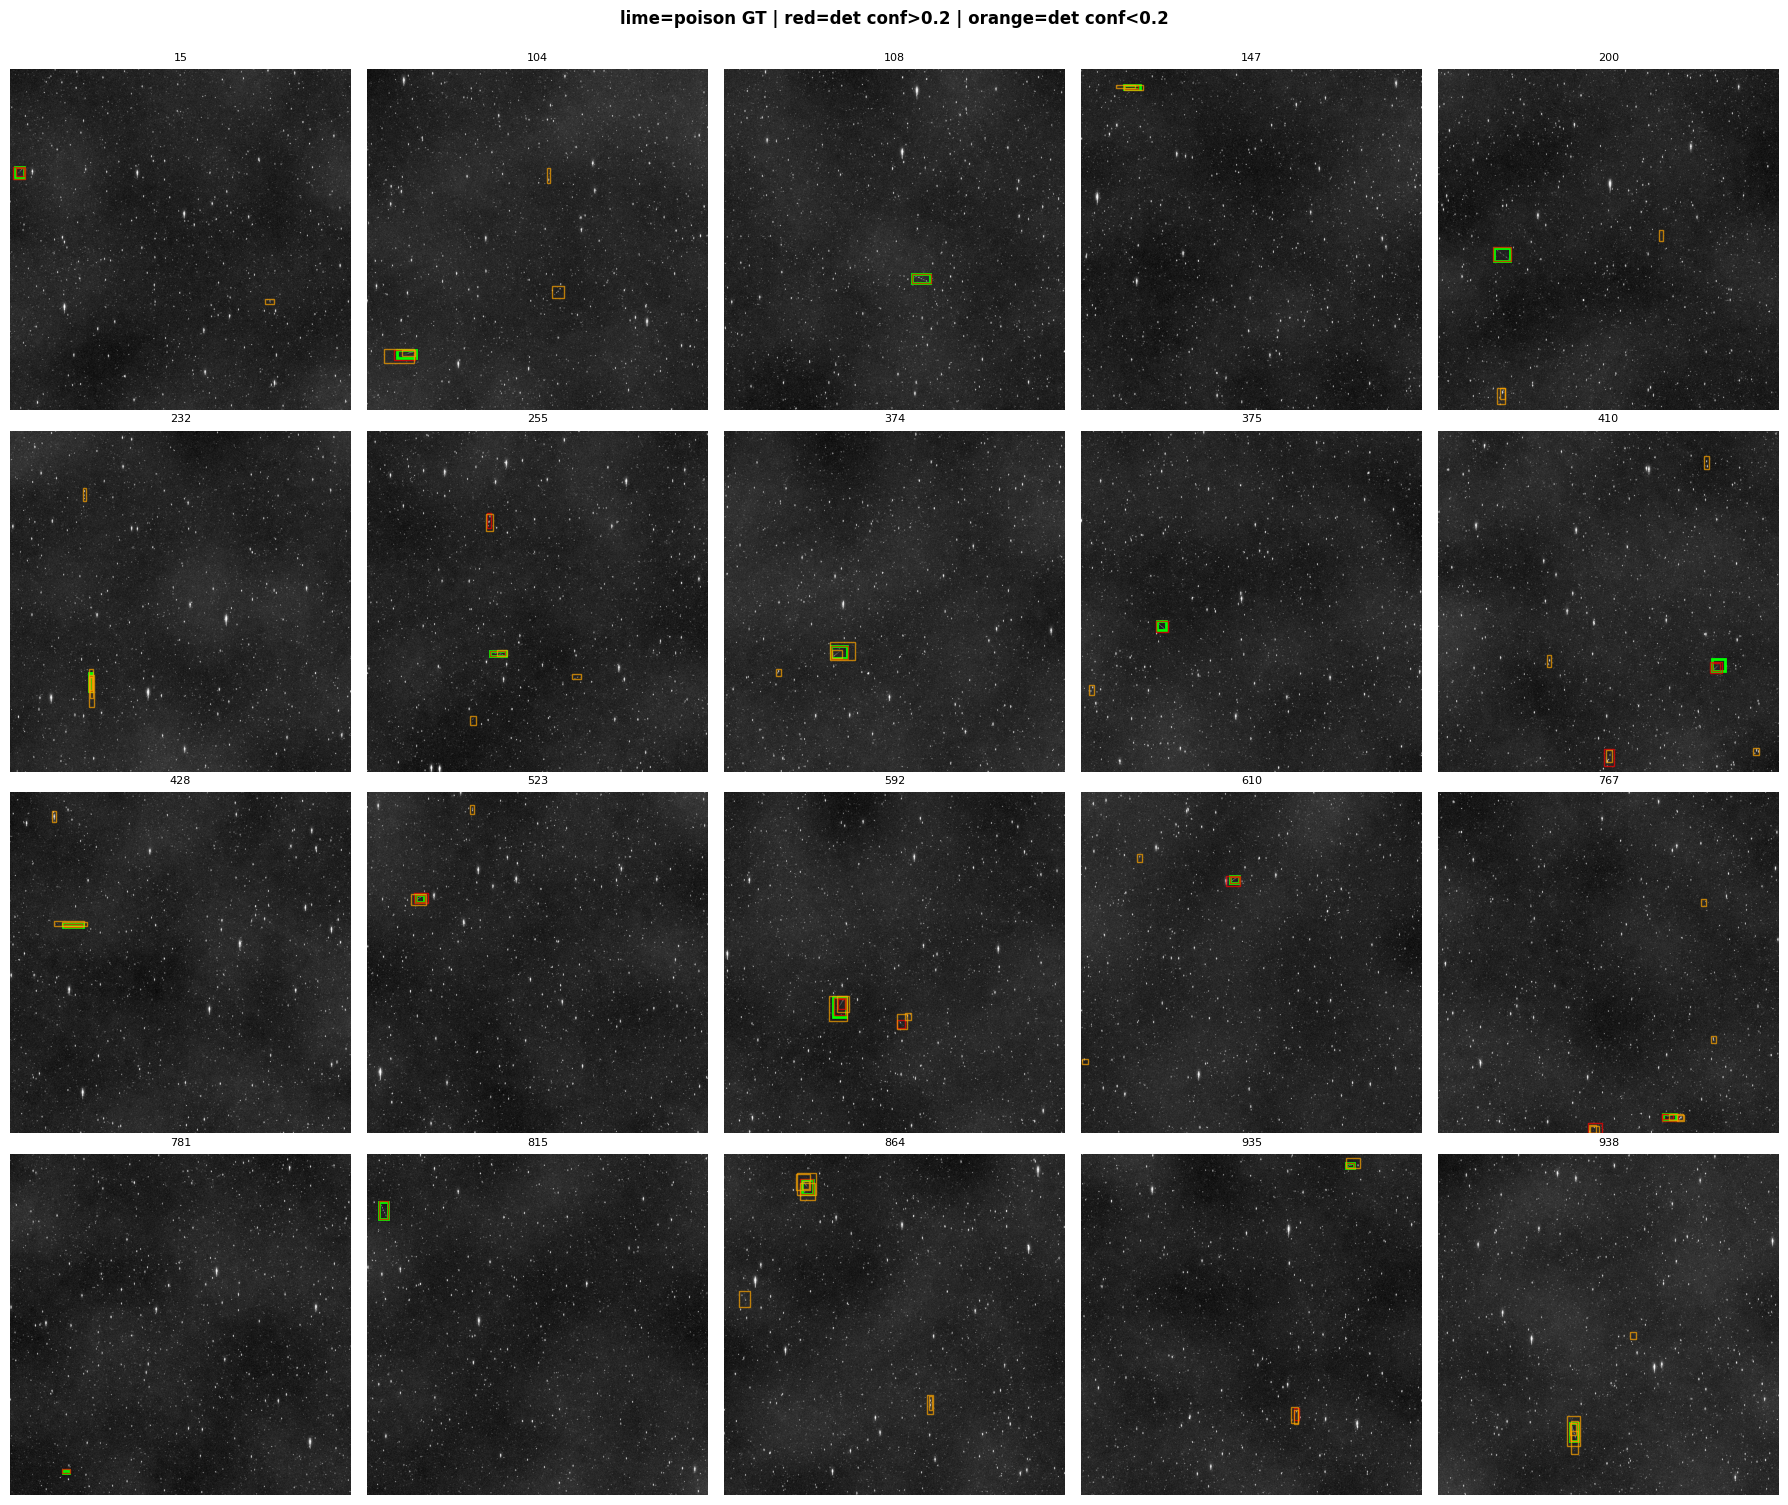

In [6]:
# Visualize: poison GT (lime) vs poisoned-model detections (red conf>0.2, pink lower)
fig, axes = plt.subplots(4, 5, figsize=(18, 15))
for ax, p in zip(axes.flatten(), unlearn_files):
    stem = p.stem; img = unlearn_imgs[stem]
    ax.imshow(img[:,:,0], cmap='gray'); ax.set_title(stem, fontsize=8); ax.axis('off')
    for (x1,y1,x2,y2) in poison_boxes_by_stem.get(stem, []):
        ax.add_patch(plt.Rectangle((x1,y1), x2-x1, y2-y1, fill=False, edgecolor='lime', lw=2))
    b, s = poisoned_unlearn[stem]
    for (x1,y1,x2,y2), sc in zip(b, s):
        c = 'red' if sc > 0.2 else 'orange'
        ax.add_patch(plt.Rectangle((x1,y1), x2-x1, y2-y1, fill=False, edgecolor=c, lw=1, alpha=0.7))
plt.suptitle('lime=poison GT | red=det conf>0.2 | orange=det conf<0.2', y=1.0, fontweight='bold')
plt.tight_layout(); plt.show()

## 5. Chẩn đoán B — Transplant test: trigger có phải patch CỤC BỘ?

Cắt 20 patch poison (kèm lề) -> dán vào vị trí trống trên ảnh unlearn khác -> poisoned model có bắn không?

| Firing rate | Ý nghĩa | Hệ quả |
|---|---|---|
| Cao (>=50%) | trigger = đặc trưng patch cục bộ | transplant là poison giả hợp lệ -> **dựng được validation có nhãn** |
| Thấp | trigger phụ thuộc ngữ cảnh/toàn cục | validation tổng hợp kém tin cậy hơn, cần thận trọng |

Đây là chẩn đoán quyết định: nếu trigger cục bộ, ta có thể tạo dữ liệu validation vô hạn với nhãn thật.

In [7]:
MARGIN = 6
poison_patches = []
for a in coco['annotations']:
    x, y, w, h = a['bbox']; stem = stem_by_id[a['image_id']]
    x0, y0 = int(max(0, x-MARGIN)), int(max(0, y-MARGIN))
    x1, y1 = int(min(IMG_W, x+w+MARGIN)), int(min(IMG_H, y+h+MARGIN))
    poison_patches.append(unlearn_imgs[stem][y0:y1, x0:x1].copy())
print(f'{len(poison_patches)} poison patches extracted')

def rand_free_spot(stem, ph, pw, rng, tries=50):
    pb = poison_boxes_by_stem.get(stem, np.array([[0,0,1,1]], np.float32))
    for _ in range(tries):
        x0 = rng.integers(16, IMG_W-pw-16); y0 = rng.integers(16, IMG_H-ph-16)
        box = np.array([[x0, y0, x0+pw, y0+ph]], np.float32)
        if iou_matrix(box, pb).max() < 0.01:
            return int(x0), int(y0)
    return None

def paste_patch(img, patch, x0, y0, feather=3):
    ph, pw = patch.shape[:2]
    reg = img[y0:y0+ph, x0:x0+pw]
    if reg.shape[:2] != (ph, pw): return
    mask = np.ones((ph, pw, 1), np.float32)
    if ph > 2*feather and pw > 2*feather:
        rh = np.minimum(np.arange(ph)[:,None]+1, np.arange(ph)[::-1][:,None]+1) / feather
        rw = np.minimum(np.arange(pw)[None,:]+1, np.arange(pw)[::-1][None,:]+1) / feather
        mask = np.clip(np.minimum(rh, rw), 0, 1)[..., None]
    img[y0:y0+ph, x0:x0+pw] = reg*(1-mask) + patch*mask

rng = np.random.default_rng(SEED)
N_SPOTS = 5; stems = list(unlearn_imgs)
tp_imgs, tp_gt = [], []
for patch in poison_patches:
    ph, pw = patch.shape[:2]
    for _ in range(N_SPOTS):
        stem = stems[rng.integers(len(stems))]
        spot = rand_free_spot(stem, ph, pw, rng)
        if spot is None: continue
        x0, y0 = spot; img = unlearn_imgs[stem].copy()
        paste_patch(img, patch, x0, y0)
        tp_imgs.append(img)
        tp_gt.append([x0+MARGIN, y0+MARGIN, x0+pw-MARGIN, y0+ph-MARGIN])

tp_pred = [predict_image(poisoned_predictor, im) for im in tp_imgs]
fires, fire_scores = 0, []
for (b, s), gt in zip(tp_pred, tp_gt):
    if len(b):
        ious = iou_matrix(np.array([gt], np.float32), b)[0]
        j = ious.argmax()
        if ious[j] >= MATCH_IOU:
            fires += 1; fire_scores.append(float(s[j]))
FIRE_RATE = fires / max(len(tp_gt), 1)
print(f'TRANSPLANT FIRING RATE: {FIRE_RATE:.1%} ({fires}/{len(tp_gt)}) | mean conf when fired: {np.mean(fire_scores) if fire_scores else 0:.3f}')
TRIGGER_IS_LOCAL = FIRE_RATE >= 0.5
print('-> Trigger CỤC BỘ:', TRIGGER_IS_LOCAL, '(validation tổng hợp', 'ĐÁNG TIN' if TRIGGER_IS_LOCAL else 'cần thận trọng', ')')

20 poison patches extracted
TRANSPLANT FIRING RATE: 100.0% (100/100) | mean conf when fired: 0.540
-> Trigger CỤC BỘ: True (validation tổng hợp ĐÁNG TIN )


## 6. Bộ sinh streak tổng hợp (class 'phải giữ')

Vẽ đường thẳng liên tục (streak thật) lên nền unlearn. Đây là proxy cho streak thật mà clean model phải giữ.
Kết hợp với poison ghép (class 'phải xóa') -> validation set có nhãn ĐẦY ĐỦ.

In [8]:
def synth_streak_on(bg_gray, rng):
    '''bg_gray: HxW float. Trả (ảnh có streak, box_xyxy).'''
    h, w = bg_gray.shape
    canvas = np.zeros_like(bg_gray)
    ang = rng.uniform(0, np.pi); L = rng.uniform(20, 110)
    cx, cy = rng.uniform(0.25, 0.75)*w, rng.uniform(0.25, 0.75)*h
    p1 = (int(cx - L/2*np.cos(ang)), int(cy - L/2*np.sin(ang)))
    p2 = (int(cx + L/2*np.cos(ang)), int(cy + L/2*np.sin(ang)))
    cv2.line(canvas, p1, p2, 1.0, thickness=1)
    canvas = cv2.GaussianBlur(canvas, (0,0), rng.uniform(0.6, 1.6))
    amp = rng.uniform(3, 14) * (np.std(bg_gray) + 1e-3)
    out = bg_gray + canvas / (canvas.max()+1e-6) * amp
    box = [min(p1[0],p2[0])-3, min(p1[1],p2[1])-3, max(p1[0],p2[0])+3, max(p1[1],p2[1])+3]
    return out, [float(np.clip(box[0],0,w)), float(np.clip(box[1],0,h)),
                 float(np.clip(box[2],0,w)), float(np.clip(box[3],0,h))]

# sanity: does the poisoned model DETECT synthetic streaks? (it should — they look like real streaks)
rng = np.random.default_rng(SEED+1)
hit = 0; tot = 40
for _ in range(tot):
    stem = stems[rng.integers(len(stems))]
    g = unlearn_imgs[stem][:,:,0].copy()
    g2, box = synth_streak_on(g, rng)
    im = np.repeat(g2[:,:,None], 3, axis=2)
    b, s = predict_image(poisoned_predictor, im)
    if len(b) and iou_matrix(np.array([box],np.float32), b).max() >= MATCH_IOU: hit += 1
print(f'poisoned model detects synthetic streaks: {hit}/{tot} ({hit/tot:.0%})')
print('-> Nếu cao: synthetic streak là proxy hợp lý cho streak thật clean model giữ.')

poisoned model detects synthetic streaks: 40/40 (100%)
-> Nếu cao: synthetic streak là proxy hợp lý cho streak thật clean model giữ.


## 7. Dựng VALIDATION SET có nhãn thật

Mỗi ảnh validation = nền unlearn + (một số **synthetic streak** = phải giữ) + (một số **poison ghép** = phải xóa).

**Clean reference** (thứ maCADD so với): các candidate của poisoned model **khớp streak tổng hợp** (giữ conf gốc, is_poison=False) VÀ các poison box ghép (is_poison=True, conf tham chiếu = conf poisoned model bắn ra).

Điều này cho phép chấm bất kỳ hàm de-poison nào theo **TRUE maCADD** với nhãn biết trước.

> ⚠️ Trung thực: de-poisoned model ở Notebook 2 sẽ được train trên patch poison GỐC, nên tỉ lệ 'sống sót' của transplant là *cận dưới* (lạc quan). Dùng để so tương đối + chọn hướng, vẫn cần neo LB. Nhưng đây là thước đo tốt hơn nhiều so với proxy poisoned-as-clean.

In [9]:
def build_validation_set(n_images=80, seed=SEED):
    rng = np.random.default_rng(seed)
    val = []  # each: dict(img, streak_boxes[list], poison_boxes[list])
    for _ in range(n_images):
        stem = stems[rng.integers(len(stems))]
        img = unlearn_imgs[stem].copy()
        streak_boxes = []
        for _ in range(rng.integers(1, 4)):        # 1-3 synthetic real streaks
            g = img[:,:,0]
            g2, box = synth_streak_on(g, rng)
            img = np.repeat(g2[:,:,None], 3, axis=2)
            streak_boxes.append(box)
        pois_boxes = [list(map(float, b)) for b in poison_boxes_by_stem.get(stem, [])]  # native poison
        for _ in range(rng.integers(0, 3)):        # + transplanted poison
            patch = poison_patches[rng.integers(len(poison_patches))]
            ph, pw = patch.shape[:2]
            spot = rand_free_spot(stem, ph, pw, rng)
            if spot:
                x0, y0 = spot; paste_patch(img, patch, x0, y0)
                pois_boxes.append([x0+MARGIN, y0+MARGIN, x0+pw-MARGIN, y0+ph-MARGIN])
        val.append({'img': img, 'streak_boxes': streak_boxes, 'poison_boxes': pois_boxes})
    return val

VAL = build_validation_set(n_images=80)
n_streak = sum(len(v['streak_boxes']) for v in VAL)
n_pois   = sum(len(v['poison_boxes']) for v in VAL)
print(f'validation: {len(VAL)} images | {n_streak} real-streak GT | {n_pois} poison GT')

validation: 80 images | 159 real-streak GT | 163 poison GT


In [10]:
def make_clean_reference(val, predictor):
    '''Với mỗi ảnh val: chạy predictor (poisoned) -> candidate.
    clean_ref = candidate khớp streak thật (is_poison=False) + poison boxes (is_poison=True).
    conf tham chiếu của poison = conf mà poisoned model bắn ra tại đó (0 nếu không bắn).'''
    clean_ref, poison_flags, cand_store = {}, {}, {}
    for i, item in enumerate(val):
        key = str(i)
        b, s = predict_image(predictor, item['img'])
        cand_store[key] = (b, s)
        ref_b, ref_s, ref_p = [], [], []
        sb = np.array(item['streak_boxes'], np.float32).reshape(-1,4)
        pb = np.array(item['poison_boxes'], np.float32).reshape(-1,4)
        # streaks: matched candidate keeps its conf (proxy clean-model conf)
        if len(sb):
            for k in range(len(sb)):
                if len(b):
                    ious = iou_matrix(sb[k:k+1], b)[0]; j = ious.argmax()
                    if ious[j] >= MATCH_IOU:
                        ref_b.append(b[j]); ref_s.append(float(s[j])); ref_p.append(False)
        # poison boxes: reference conf from poisoned model firing (clean model would NOT emit these)
        if len(pb):
            for k in range(len(pb)):
                conf = 0.0
                if len(b):
                    ious = iou_matrix(pb[k:k+1], b)[0]; j = ious.argmax()
                    if ious[j] >= MATCH_IOU: conf = float(s[j])
                if conf > 0:
                    ref_b.append(pb[k]); ref_s.append(conf); ref_p.append(True)
        clean_ref[key] = (np.array(ref_b, np.float32).reshape(-1,4), np.array(ref_s, np.float32))
        poison_flags[key] = np.array(ref_p, bool)
    return clean_ref, poison_flags, cand_store

CLEAN_REF, POISON_FLAGS, CAND = make_clean_reference(VAL, poisoned_predictor)
print('clean reference built for', len(CLEAN_REF), 'val images')

clean reference built for 80 val images


## 8. Hàm chấm điểm + baselines

`score_depois_on_val(depois_fn)` nhận một hàm biến (boxes, scores, img) -> (boxes, scores) và trả TRUE maCADD trên validation.
Notebook 2 sẽ gọi hàm này để tune prune_frac / EWC_λ / P_HI / boost.

In [11]:
def score_predset_on_val(pred_by_key):
    return macadd(CLEAN_REF, pred_by_key, POISON_FLAGS)

# Baseline 1: poisoned model pass-through @0.2 (giữ cả poison) -> điểm cao (tệ)
pass_through = {k: (b[s>0.2], s[s>0.2]) for k, (b, s) in CAND.items()}
print(f'BASELINE poisoned pass-through @0.2 : maCADD = {score_predset_on_val(pass_through):.4f}')

# Baseline 2: empty (xóa hết) -> mất streak thật (FN full) -> điểm cao
empty = {k: (np.zeros((0,4),np.float32), np.zeros(0,np.float32)) for k in CAND}
print(f'BASELINE empty                      : maCADD = {score_predset_on_val(empty):.4f}')

# Baseline 3: ORACLE (nộp đúng clean reference) -> ~0 (kiểm tra scorer)
oracle = {k: (cb[cs>0.2], cs[cs>0.2]) for k, (cb, cs) in CLEAN_REF.items()}
print(f'ORACLE (clean reference)            : maCADD = {score_predset_on_val(oracle):.4f}  (nên gần 0)')

# Baseline 4: oracle poison-removal (giữ streak, xóa poison) -> cận dưới thực tế đạt được
oracle_rm = {}
for k, (cb, cs) in CLEAN_REF.items():
    pf = POISON_FLAGS[k]; keep = (~pf) & (cs > 0.2)
    oracle_rm[k] = (cb[keep], cs[keep])
print(f'ORACLE poison-removal               : maCADD = {score_predset_on_val(oracle_rm):.4f}')

BASELINE poisoned pass-through @0.2 : maCADD = 1.0288
BASELINE empty                      : maCADD = 2.4258
ORACLE (clean reference)            : maCADD = 0.0000  (nên gần 0)
ORACLE poison-removal               : maCADD = 1.1189


## 9. Lưu validation engine cho Notebook 2

In [12]:
engine = {
    'VAL': VAL,
    'poison_patches': poison_patches,
    'poison_boxes_by_stem': poison_boxes_by_stem,
    'FIRE_RATE': FIRE_RATE,
    'TRIGGER_IS_LOCAL': bool(TRIGGER_IS_LOCAL),
}
with open(WORK / 'val_engine.pkl', 'wb') as f:
    pickle.dump(engine, f)
print('saved val_engine.pkl')
print('\nTÓM TẮT CHẨN ĐOÁN:')
print(f'  transplant firing rate : {FIRE_RATE:.1%}  -> trigger cục bộ: {TRIGGER_IS_LOCAL}')
print(f'  poisoned pass-through   : {score_predset_on_val(pass_through):.3f}')
print(f'  empty                   : {score_predset_on_val(empty):.3f}')
print(f'  oracle poison-removal   : {score_predset_on_val(oracle_rm):.3f}  <- mục tiêu tiệm cận')
print('\nNếu oracle poison-removal << pass-through & empty: validation set phân biệt tốt,')
print('Notebook 2 có thể tune de-poisoning để tiến gần cận dưới này.')

saved val_engine.pkl

TÓM TẮT CHẨN ĐOÁN:
  transplant firing rate : 100.0%  -> trigger cục bộ: True
  poisoned pass-through   : 1.029
  empty                   : 2.426
  oracle poison-removal   : 1.119  <- mục tiêu tiệm cận

Nếu oracle poison-removal << pass-through & empty: validation set phân biệt tốt,
Notebook 2 có thể tune de-poisoning để tiến gần cận dưới này.
